In [ ]:
import kagglehub
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models, Model

In [ ]:
path = kagglehub.dataset_download("rishianand/devanagari-character-set")


100%|██████████| 118M/118M [00:06<00:00, 18.7MB/s]

Extracting files...


['70699.png', '87320.png', '14041.png', '45619.png', '52298.png', '70686.png', '1030.png', '14038.png', '45716.png', '7959.png', '1038.png', '14018.png', '985.png', '45707.png', '7972.png', '10843.png', '32662.png', '32822.png', '80753.png', '17008.png', '80857.png', '80757.png', '8000.png', '14124.png', '32832.png', '32692.png', '52307.png', '32782.png', '14052.png', '13898.png', '45678.png', '32765.png', '59228.png', '24542.png', '80871.png', '32844.png', '14085.png', '70689.png', '10873.png', '59226.png', '53887.png', '59255.png', '32674.png', '85946.png', '72378.png', '59263.png', '1065.png', '45754.png', '24621.png', '59351.png', '85318.png', '13999.png', '59273.png', '6279.png', '80780.png', '59185.png', '13872.png', '45628.png', '16959.png', '59206.png', '45724.png', '13921.png', '59197.png', '87338.png', '32645.png', '44111.png', '59213.png', '59171.png', '6277.png', '1077.png', '1072.png', '59195.png', '13992.png', '1043.png', '80768.png', '87345.png', '17022.png', '14122.png'

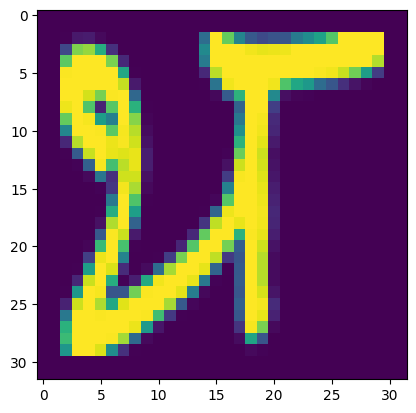

In [ ]:
printpath = os.path.join(path, "Images", "Images", "character_17_tha")
print(os.listdir(printpath))
print(os.listdir(printpath))

img = Image.open(os.path.join(printpath, "87320.png"))
print(img.size)
print(img.mode)
plt.imshow(img)

In [ ]:
data_dir = os.path.join(path, "Images", "Images")
dataset = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    image_size=(32, 32),
    color_mode="grayscale",
    batch_size=32,
    label_mode="int"
)
class_names = dataset.class_names
dataset = dataset.map(lambda X, y: (X / 255.0, y))
print(class_names)
print("Total classes:", len(class_names))

Found 92000 files belonging to 46 classes.
['character_01_ka', 'character_02_kha', 'character_03_ga', 'character_04_gha', 'character_05_kna', 'character_06_cha', 'character_07_chha', 'character_08_ja', 'character_09_jha', 'character_10_yna', 'character_11_taamatar', 'character_12_thaa', 'character_13_daa', 'character_14_dhaa', 'character_15_adna', 'character_16_tabala', 'character_17_tha', 'character_18_da', 'character_19_dha', 'character_20_na', 'character_21_pa', 'character_22_pha', 'character_23_ba', 'character_24_bha', 'character_25_ma', 'character_26_yaw', 'character_27_ra', 'character_28_la', 'character_29_waw', 'character_30_motosaw', 'character_31_petchiryakha', 'character_32_patalosaw', 'character_33_ha', 'character_34_chhya', 'character_35_tra', 'character_36_gya', 'digit_0', 'digit_1', 'digit_2', 'digit_3', 'digit_4', 'digit_5', 'digit_6', 'digit_7', 'digit_8', 'digit_9']
Total classes: 46


In [ ]:
# Shuffle dataset
# dataset = dataset.shuffle(3000, seed=42)

# Calculate batches
total = tf.data.experimental.cardinality(dataset).numpy()

train_size = int(0.6 * total)
val_size = int(0.2 * total)

# Split
train_ds = dataset.take(train_size)
val_ds = dataset.skip(train_size).take(val_size)
test_ds = dataset.skip(train_size + val_size)

In [ ]:
def basic_block(x, filters, stride):
    shortcut = x

    out = layers.Conv2D(filters, 3, strides=stride, padding="same", use_bias=False)(x)
    out = layers.BatchNormalization()(out)
    out = layers.ReLU()(out)

    out = layers.Conv2D(filters, 3, strides=1, padding="same", use_bias=False)(out)
    out = layers.BatchNormalization()(out)

    # shortcut: match the shape when size or channels change
    if stride != 1 or x.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1, strides=stride, use_bias=False)(x)
        shortcut = layers.BatchNormalization()(shortcut)

    out = layers.Add()([out, shortcut])  # residual connection
    return layers.ReLU()(out)

In [ ]:
def build_resnet18(num_classes=46):
    inputs = layers.Input(shape=(32, 32, 1))

    # stem: 7x7 conv + max pool
    x = layers.Conv2D(64, 8, strides=2, padding="same", use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D(3, strides=2, padding="same")(x)

    # four stages, two blocks each: 64 -> 128 -> 256 -> 512
    x = basic_block(x, 512, 2)
    x = basic_block(x, 512, 1)

    x = basic_block(x, 256, 2)
    x = basic_block(x, 256, 1)

    x = basic_block(x, 128, 2)
    x = basic_block(x, 128, 1)

    x = basic_block(x, 64, 1)
    x = basic_block(x, 64, 1)







    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return Model(inputs, outputs)

In [ ]:
model = build_resnet18(num_classes=46)

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)

model.evaluate(test_ds)

Epoch 1/10
1725/1725 ━━━━━━━━━━━━━━━━━━━━ 81s 31ms/step - accuracy: 0.7911 - loss: 0.7371 - val_accuracy: 0.8855 - val_loss: 0.3799
Epoch 2/10
1725/1725 ━━━━━━━━━━━━━━━━━━━━ 58s 30ms/step - accuracy: 0.9303 - loss: 0.2354 - val_accuracy: 0.9118 - val_loss: 0.2833
Epoch 3/10
1725/1725 ━━━━━━━━━━━━━━━━━━━━ 57s 30ms/step - accuracy: 0.9516 - loss: 0.1653 - val_accuracy: 0.9374 - val_loss: 0.2166
Epoch 4/10
1725/1725 ━━━━━━━━━━━━━━━━━━━━ 58s 30ms/step - accuracy: 0.9604 - loss: 0.1319 - val_accuracy: 0.9757 - val_loss: 0.0790
Epoch 5/10
1725/1725 ━━━━━━━━━━━━━━━━━━━━ 57s 30ms/step - accuracy: 0.9678 - loss: 0.1068 - val_accuracy: 0.9758 - val_loss: 0.0774
Epoch 6/10
1725/1725 ━━━━━━━━━━━━━━━━━━━━ 58s 30ms/step - accuracy: 0.9745 - loss: 0.0846 - val_accuracy: 0.9749 - val_loss: 0.0763
Epoch 7/10
1725/1725 ━━━━━━━━━━━━━━━━━━━━ 57s 30ms/step - accuracy: 0.9781 - loss: 0.0731 - val_accuracy: 0.9816 - val_loss: 0.0586
Epoch 8/10
1725/1725 ━━━━━━━━━━━━━━━━━━━━ 57s 29ms/step - accuracy: 0.9817 -

[0.018247105181217194, 0.9947826266288757]

In [ ]:
# Extract images and labels together
X_batches = []
y_batches = []

for X, y in val_ds:
    X_batches.append(X.numpy())
    y_batches.append(y.numpy())

X_val = np.concatenate(X_batches)
y_val = np.concatenate(y_batches)

# Predict
probs = model.predict(X_val)
predicted = np.argmax(probs, axis=1)

print("Validation accuracy:", np.mean(predicted == y_val))

575/575 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step
Validation accuracy: 0.9942391304347826


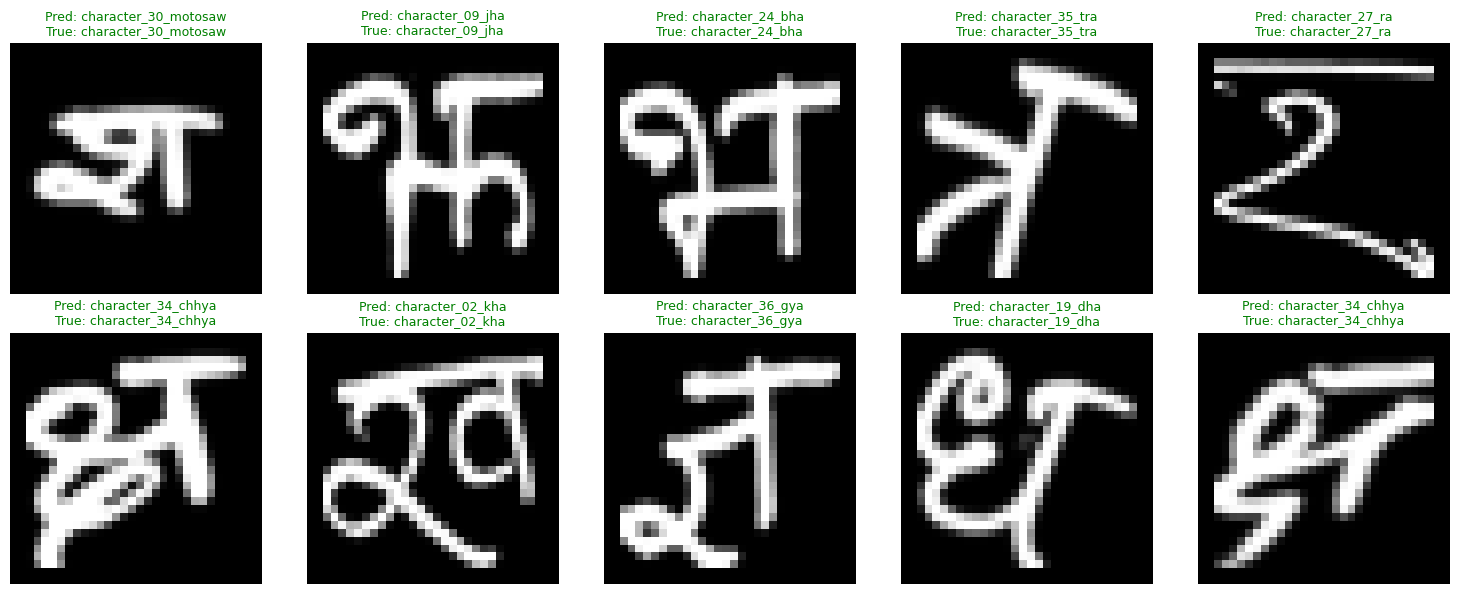

In [ ]:
plt.figure(figsize=(15, 6))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_val[i].reshape(32, 32), cmap="gray")

    pred = class_names[predicted[i]]
    actual = class_names[y_val[i]]

    color = "green" if predicted[i] == y_val[i] else "red"

    plt.title(f"Pred: {pred}\nTrue: {actual}",
              color=color, fontsize=9)

    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Save the trained model so the Flask backend can load it
model.save('devanagari_resnet18.h5')
print('Model saved to devanagari_resnet18.h5')
# Download from Colab: Files → devanagari_resnet18.h5
# Then copy it to the backend/ folder of the Mini project.
